# Rapport — Engine de traitement et d'analyse de flux de logs sécurisé

**Projet final ING3 — Python avancé.**

Ce notebook est le rapport synthétique du projet. Il **importe le package `engine`**
(aucune duplication de code) et l'exécute sur les jeux de données fournis :

1. présentation et architecture ;
2. démonstration de chaque module (extrait de code + sortie) ;
3. graphiques d'analyse ;
4. benchmark mémoire (mémoire pic vs nombre de lignes) ;
5. correspondance barème → code (générée par introspection) ;
6. limites et améliorations.

## 1. Présentation et architecture

Le moteur lit des fichiers de logs hétérogènes (JSON, texte brut, connexions),
les nettoie, les normalise, les route, agrège des indicateurs de sécurité en
**une seule passe** et applique un moteur de règles configurable. Toutes les étapes
sont des **itérateurs paresseux** : la mémoire ne dépend pas de la taille des fichiers.

```
 data/samples/*.log
        │
        ▼
 ingestion.read_multiple_sources ── yield / yield from (1 ligne en mémoire)
        │
        ▼
 map(str.strip) ─► filter(None) ─────────── lignes vides éliminées
        │
        ▼
 parsing.parse_stream ───────────── dict LogRecord + tuple (IP, Port, Proto)
        │                           LogParseError comptée, pipeline jamais stoppé
        ▼
 filter(lambda) ×3 ──────────────── niveau valide / IP valide / horodatage non nul
        │
        ▼
 map(normalize_record) ─► map(route_record) ─── f-strings, match-case
        │
        ▼
 analytics.StreamAggregator ─────── set / frozenset (| & - ^), defaultdict
        │                           detection.detect_brute_force (for/while/break/else)
        ▼
 rules.apply_security_rules(*rules, **config)
        │
        ▼
 report (JSON signé HMAC + console)   audit (globals()/locals())
```

| Module | Rôle |
|---|---|
| `engine/ingestion.py` | générateurs de lignes (`yield`, `yield from`) |
| `engine/parsing.py` | ligne → `LogRecord` (dict) + tuple immuable |
| `engine/pipeline.py` | `filter`, `map`, `lambda`, `match-case` |
| `engine/analytics.py` | ensembles, `defaultdict`, agrégation en une passe |
| `engine/detection.py` | force brute : `for` + `while` + `break`/`continue`/`else` |
| `engine/rules.py` | règles de première classe, `*args` / `**kwargs` |
| `engine/audit.py` | introspection `globals()` / `locals()` |
| `engine/report.py` | rapport JSON signé, synthèse console, benchmark |

In [1]:
import inspect
import json
import sys
from datetime import timedelta
from itertools import islice
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "engine").is_dir():  # notebook lancé depuis notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import engine
from engine import analytics, audit, detection, ingestion, parsing, pipeline, rules
from engine.analytics import StreamAggregator, compare_ip_sets, load_blacklist
from engine.report import format_benchmark, run_scaling_benchmark
from engine.models import PipelineStats, SecurityEvent

SAMPLES = ROOT / "data" / "samples"
BLACKLIST_PATH = ROOT / "data" / "blacklist.txt"
BIG = ROOT / "data" / "big"
TRUTH = json.loads((SAMPLES / "ground_truth.json").read_text(encoding="utf-8"))
print(f"engine v{engine.__version__} — Python {sys.version.split()[0]}")
print("Sources :", [p.name for p in ingestion.discover_sources(SAMPLES)])

engine v1.0.0 — Python 3.11.4
Sources : ['server_01.log', 'server_02.log', 'server_03.log']


In [2]:
# Charte graphique des figures (palette catégorielle validée : bleu / orange)
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
SERIES_1, SERIES_2 = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "figure.dpi": 110,
})


def fmt(n: float) -> str:
    return f"{n:,.0f}".replace(",", " ")


def hbar(ax, labels, values, color=SERIES_1, label_fmt=fmt):
    # Barres horizontales fines, séparées par un liseré de 2 px, valeurs en bout de barre
    bars = ax.barh(labels, values, color=color, height=0.62, edgecolor=SURFACE, linewidth=2)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    for bar, value in zip(bars, values):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, "  " + label_fmt(value),
                va="center", color=INK_2, fontsize=9)
    ax.set_xlim(0, max(values) * 1.15 if len(values) else 1)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: fmt(value)))
    return bars

## 2. Démonstration des modules

### MODULE 1 — Ingestion par générateurs et parsing

`read_log_file` est une **fonction génératrice** : rien n'est lu tant qu'on ne
consomme pas le flux, et une seule ligne est en mémoire à la fois.
`read_multiple_sources` enchaîne les fichiers avec `yield from`.

In [3]:
print(inspect.getsource(ingestion.read_multiple_sources))
stream = ingestion.read_multiple_sources(ingestion.discover_sources(SAMPLES))
print("inspect.isgenerator(stream) =", inspect.isgenerator(stream))
for line in islice(stream, 3):  # consommation partielle : 3 lignes seulement
    print("  ", line[:100])
stream.close()

def read_multiple_sources(paths: Iterable[Path]) -> Iterator[str]:
    """Enchaîne plusieurs sources en un seul flux grâce à ``yield from``.

    ``yield from read_log_file(path)`` délègue l'itération au sous-générateur :
    chaque ligne est transmise directement au consommateur, sans liste
    intermédiaire. Une source manquante ou illisible est signalée par un
    *warning* puis ignorée : le flux continue avec la source suivante.
    """
    for path in paths:
        try:
            yield from read_log_file(path)
        except LogSourceError as exc:
            logger.warning("%s -> source ignorée", exc)
            continue

inspect.isgenerator(stream) = True
   2026-11-05T00:00:04 | INFO | 192.168.1.114 | user_014 | {"event": "config_change", "port": 22, "prot
   2026-11-05T00:00:41 | INFO | 77.226.182.44 | user_023 | GET /api/v1/users 200
   2026-11-05T00:01:08 | INFO | 172.16.27.109 | user_048 | {"event": "login_success", "port": 3389, "pr


In [4]:
# Les 3 formats -> dict LogRecord ; métadonnées de connexion -> tuple immuable
examples = [
    '2026-11-07T10:15:32 | ERROR | 192.168.1.45 | user_042 | {"event": "login_failed", "port": 22, "proto": "TCP", "code": 401}',
    "2026-11-07T10:15:33 | INFO | 10.0.0.12 | user_007 | GET /index.html 200",
    "2026-11-07T10:15:34 | WARNING | 172.16.0.8 | user_013 | CONN 172.16.0.8:443/TCP",
]
for raw in examples:
    record = parsing.parse_line(raw)
    print(f"{record['source_format']:<10} payload={type(record['payload']).__name__:<4} "
          f"connection={record['connection']}")

connection = parsing.parse_line(examples[2])["connection"]
try:
    connection[1] = 80  # un tuple est immuable
except TypeError as exc:
    print("Immutabilité du tuple :", type(exc).__name__, "-", exc)

for bad in ["2026-11-07T10:15:37 | INFO | 10.0.0", "2026-11-07T10:15:39 | DEBUGX | 10.0.0.16 | u | GET / 200"]:
    try:
        parsing.parse_line(bad)
    except parsing.LogParseError as exc:
        print(f"LogParseError [{exc.reason}] : {exc}")

json       payload=dict connection=('192.168.1.45', 22, 'TCP')
text       payload=str  connection=None
connection payload=str  connection=('172.16.0.8', 443, 'TCP')
Immutabilité du tuple : TypeError - 'tuple' object does not support item assignment
LogParseError [fields] : 3 champ(s) au lieu de 5
LogParseError [level] : niveau inconnu 'DEBUGX'


### MODULE 2 — Pipeline fonctionnel et routage `match-case`

`build_pipeline` compose `map(str.strip)`, `filter(None)`, trois `filter(lambda …)`,
`map(normalize_record)` et `map(route_record)`. Chaque étape est comptée au passage.

In [5]:
source = inspect.getsource(pipeline.build_pipeline)
print(source[source.index("    stats = stats"):])

    stats = stats if stats is not None else PipelineStats()
    lines: Iterator[str] = read_multiple_sources(sources)
    if limit is not None:
        lines = islice(lines, limit)
    lines = count_stage(lines, stats, STAGE_READ)
    lines = count_stage(drop_empty(strip_lines(lines)), stats, STAGE_NON_EMPTY)
    parsed = parse_stream(lines, strict=strict, stats=stats)
    records = count_stage(parsed, stats, STAGE_PARSED)

    # Prédicat 1 — « niveau valide » : INFO / WARNING / ERROR / CRITICAL (casse libre)
    records = filter(lambda r: r["level"].strip().upper() in VALID_LEVELS, records)
    records = count_stage(records, stats, STAGE_VALID_LEVEL)
    # Prédicat 2 — « IP valide » : adresse IPv4 / IPv6 reconnue par ipaddress
    records = filter(lambda r: is_valid_ip(r["ip"]), records)
    records = count_stage(records, stats, STAGE_VALID_IP)
    # Prédicat 3 — « horodatage non nul » : strictement postérieur à l'epoch
    records = filter(lambda r: r["timestamp"] > NULL_TIMESTAMP, r

In [6]:
stats = PipelineStats()
records = pipeline.build_pipeline(ingestion.discover_sources(SAMPLES), stats=stats)
print("Avant consommation, lignes lues :", stats.lines_read, "(évaluation paresseuse)")
first = next(records)
print("Premier enregistrement normalisé :", first["message"], "| route :", first["route"])

Avant consommation, lignes lues : 0 (évaluation paresseuse)
Premier enregistrement normalisé : 2026-11-05 00:00:04 [INFO    ]   192.168.1.114 user_014   config_change (code=200) | route : event.info


In [7]:
print(inspect.getsource(pipeline.route_entry))
for entry in ["GET /admin 200", "free text", {"level": "CRITICAL", "code": 503},
              {"level": "ERROR", "code": 401, "event": "login_failed"},
              {"level": "INFO", "event": "file_access"}, ("10.0.0.1", 3389, "TCP"),
              ("10.0.0.1", 443, "TCP"), 42]:
    print(f"{str(entry):<55} -> {pipeline.route_entry(entry)}")

def route_entry(entry: object) -> str:
    """Route une entrée selon sa STRUCTURE, uniquement avec ``match-case``.

    Aucun ``if/elif/else`` : la décision repose sur des patterns de classe
    (``str()``), de mapping (``{"level": ...}``), de séquence (tuple), des
    alternatives (``|``), des captures (``as``, ``int(code)``) et des guards.
    """
    match entry:
        # 1) Chaîne brute — guard : la chaîne commence par une méthode HTTP
        case str() as raw if raw.split(" ", 1)[0] in HTTP_METHODS:
            return ROUTE_HTTP
        case str():
            return ROUTE_TEXT
        # 2) Dict d'erreur serveur : alternative "ERROR" | "CRITICAL", capture du
        #    code entier, guard code >= 500
        case {"level": "ERROR" | "CRITICAL", "code": int(code)} if code >= 500:
            return ROUTE_SERVER_ERROR
        # 2 bis) Événement de sécurité : alternatives sur le niveau ET l'événement
        case {
            "level": "ERROR" | "CRITICAL" | "WARNING",
           

### MODULE 3 — Agrégation en une passe, ensembles et force brute

Le flux est un générateur consommable **une seule fois** : `StreamAggregator` met à
jour tous les `set` et `defaultdict` à chaque enregistrement. Les tampons de
connexion par IP sont analysés puis libérés au fil de l'eau (mémoire bornée).

In [8]:
blacklist = load_blacklist(BLACKLIST_PATH)
stats = PipelineStats()
aggregator = StreamAggregator(blacklist=blacklist)
aggregator.consume(pipeline.build_pipeline(ingestion.discover_sources(SAMPLES), stats=stats))

print(f"Lignes lues {fmt(stats.lines_read)} | vides {stats.empty_lines} | "
      f"rejetées {stats.rejected} | valides {fmt(stats.valid_records)}")
print("Vérité terrain :", TRUTH["totals"])
print("type(blacklist) =", type(blacklist).__name__, "| type(level_counts) =",
      type(aggregator.level_counts).__name__)
print("Clé jamais vue -> 0 (pas de KeyError) :", aggregator.level_counts["DEBUG"])
ip_sets = aggregator.ip_sets()
for name, ips in ip_sets.items():
    print(f"  {name:<24} {len(ips):>4}")

Lignes lues 30 000 | vides 186 | rejetées 428 | valides 29 386
Vérité terrain : {'lines': 30000, 'empty': 186, 'rejected': 428, 'valid': 29386}
type(blacklist) = frozenset | type(level_counts) = defaultdict
Clé jamais vue -> 0 (pas de KeyError) : 0
  union                     270
  blacklisted_active         10
  active_not_blacklisted    255
  blacklisted_dormant         5
  symmetric_difference      260


In [9]:
print(inspect.getsource(detection.detect_brute_force)[-2600:])

            continue  # CONTINUE : une fenêtre ne s'ouvre que sur un échec

            failures = 0
            last_failure = start
            resume = index + 1  # par défaut : la fenêtre glisse d'un événement
            if trace is not None:
                trace.windows_scanned += 1

            # BOUCLE FOR imbriquée : parcours des événements de la fenêtre
            for position in range(index, len(events)):
                event = events[position]
                if event.event not in LOGIN_EVENTS:
                    continue  # CONTINUE : pas une tentative de connexion
                elapsed = (event.timestamp - start.timestamp).total_seconds()
                if elapsed > window_seconds:
                    break  # BREAK : on sort de la fenêtre temporelle
                if event.event == LOGIN_SUCCESS:
                    resume = position + 1  # on reprend APRÈS le succès
                    if trace is not None:
                        trace.interrupted_sequences += 

In [10]:
# for / while / break / continue / else sur 3 scénarios
T0 = aggregator.first_seen
ev = lambda s, name, ip: SecurityEvent(T0 + timedelta(seconds=s), name, "admin", ip)
scenarios = {
    "203.0.113.1": [ev(s, "login_failed", "203.0.113.1") for s in range(0, 18, 3)],
    "203.0.113.2": [ev(0, "login_failed", "203.0.113.2"), ev(3, "login_failed", "203.0.113.2"),
                    ev(5, "file_access", "203.0.113.2"),  # continue
                    ev(6, "login_success", "203.0.113.2"),  # break : séquence interrompue
                    *[ev(s, "login_failed", "203.0.113.2") for s in (9, 12, 15)]],
    "203.0.113.3": [ev(s, "login_failed", "203.0.113.3") for s in (0, 100, 200)],
}
trace = detection.DetectionTrace()
alerts = detection.detect_brute_force(scenarios, threshold=5, window_seconds=60, trace=trace)
print("Alertes :", [(a.ip, a.count) for a in alerts])
print("Cycle complet sans attaque (branche else) :", sorted(trace.clean_ips))
print("Séquences interrompues (break sur login_success) :", trace.interrupted_sequences)

detected = {(a.ip, a.count) for a in aggregator.brute_force_alerts}
expected = {(a["ip"], a["failures"]) for a in TRUTH["expected_alerts"]}
print(f"\nÉchantillons : {len(detected)} alertes détectées, {len(expected)} attendues -> "
      f"conformité ground_truth.json : {detected == expected}")

Alertes : [('203.0.113.1', 6)]
Cycle complet sans attaque (branche else) : ['203.0.113.2', '203.0.113.3']
Séquences interrompues (break sur login_success) : 1

Échantillons : 51 alertes détectées, 51 attendues -> conformité ground_truth.json : True


### MODULE 4 — Moteur de règles et introspection

Les règles sont des fonctions passées en argument à `apply_security_rules(*args, **kwargs)`.
Chaque règle ne reçoit que les paramètres qu'elle déclare (`inspect.signature`) ; une
règle qui lève une exception n'interrompt pas les autres.

In [11]:
def rule_broken(context):
    return 1 / 0  # règle volontairement défaillante

report = rules.apply_security_rules(
    rules.rule_brute_force,
    rules.rule_critical_burst,
    rules.make_threshold_rule("CRITICAL", 20),  # fonction retournée par une fonction
    rule_broken,
    context=aggregator.context(),
    threshold=5, window_seconds=60, critical_limit=10, period_minutes=5,
)
for name, found in report.items():
    print(f"{name:<26} {len(found):>3} alerte(s)")
print("Erreurs capturées :", report.errors)

La règle 'rule_broken' a échoué : ZeroDivisionError: division by zero


rule_brute_force            51 alerte(s)
rule_critical_burst          3 alerte(s)
rule_critical_over_20        2 alerte(s)
rule_broken                  0 alerte(s)
Erreurs capturées : {'rule_broken': "La règle 'rule_broken' a échoué : ZeroDivisionError: division by zero"}


In [12]:
def demo_function():
    api_token = "tok_should_never_leak"
    threshold = 5
    return audit.audit_scope(locals(), global_vars={"db_password": "hunter2", "VERSION": 1})

result = demo_function()
print(audit.format_audit_table(result))
print("\nSecret présent dans l'export JSON ?",
      "tok_should_never_leak" in json.dumps(result) or "hunter2" in json.dumps(result))

--- caller_locals : 2 variable(s), 98 o, 1 masquée(s)
variable                   type               taille (o)  aperçu
api_token                  str                        70  ***MASQUÉ***
threshold                  int                        28  5
--- audit_locals : 6 variable(s), 792 o, 0 masquée(s)
variable                   type               taille (o)  aperçu
caller_scope               dict                      184  {'api_token': '***MASQUÉ***', 'threshold': 5}
exclude_dunders            bool                       28  True
exclude_modules            bool                       28  True
global_scope               dict                      184  {'VERSION': 1, 'db_password': '***MASQUÉ***'}
global_vars                dict                      184  {'VERSION': 1, 'db_password': '***MASQUÉ***'}
local_vars                 dict                      184  {'api_token': '***MASQUÉ***', 'threshold': 5}
--- globals : 2 variable(s), 84 o, 1 masquée(s)
variable                   type          

## 3. Graphiques d'analyse (jeu d'échantillons, 3 × 10 000 lignes)

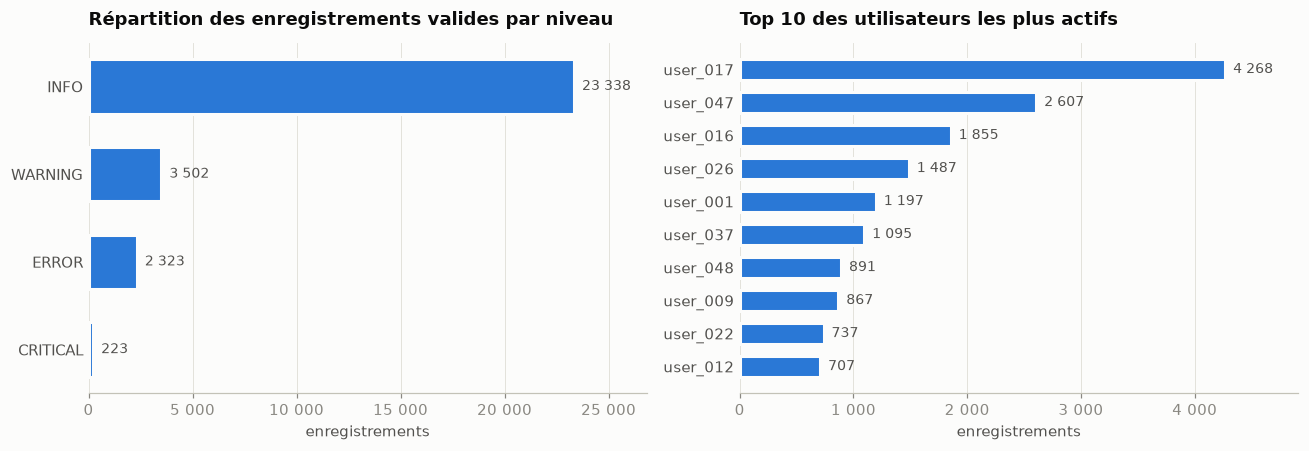

In [13]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
levels = list(aggregator.level_counts.items())
order = ["INFO", "WARNING", "ERROR", "CRITICAL"]
hbar(left, order, [aggregator.level_counts[level] for level in order])
left.set_title("Répartition des enregistrements valides par niveau")
left.set_xlabel("enregistrements")

top = aggregator.top_users(10)
hbar(right, [user for user, _ in top], [count for _, count in top])
right.set_title("Top 10 des utilisateurs les plus actifs")
right.set_xlabel("enregistrements")
fig.tight_layout()
plt.show()

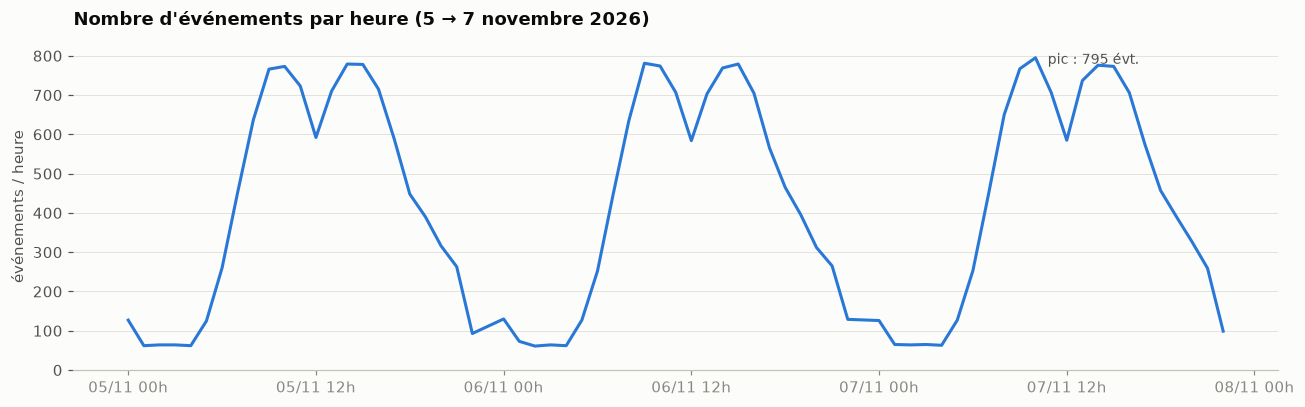

In [14]:
hours = sorted(aggregator.hourly_counts)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(hours, [aggregator.hourly_counts[h] for h in hours], color=SERIES_1, linewidth=2)
ax.set_title("Nombre d'événements par heure (5 → 7 novembre 2026)")
ax.set_ylabel("événements / heure")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
ax.grid(axis="x", visible=False)
ax.set_ylim(bottom=0)
peak = max(hours, key=aggregator.hourly_counts.__getitem__)
ax.annotate(f"pic : {aggregator.hourly_counts[peak]} évt.", (peak, aggregator.hourly_counts[peak]),
            xytext=(8, -4), textcoords="offset points", color=INK_2, fontsize=9)
fig.tight_layout()
plt.show()

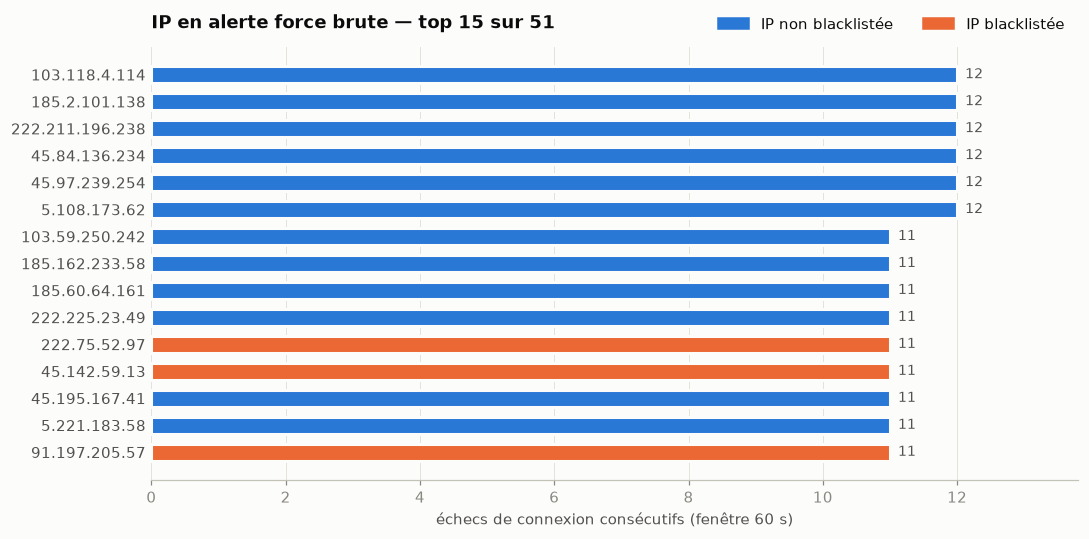

In [15]:
# IP en alerte : les 15 attaques les plus intenses, blacklistées ou non
top_alerts = sorted(aggregator.brute_force_alerts, key=lambda a: (-a.count, a.ip))[:15]
colors = [SERIES_2 if a.blacklisted else SERIES_1 for a in top_alerts]
fig, ax = plt.subplots(figsize=(10, 5))
hbar(ax, [a.ip for a in top_alerts], [a.count for a in top_alerts], color=colors)
ax.set_title(f"IP en alerte force brute — top 15 sur {len(aggregator.brute_force_alerts)}")
ax.set_xlabel("échecs de connexion consécutifs (fenêtre 60 s)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERIES_1, label="IP non blacklistée"),
                   Patch(color=SERIES_2, label="IP blacklistée")],
          loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

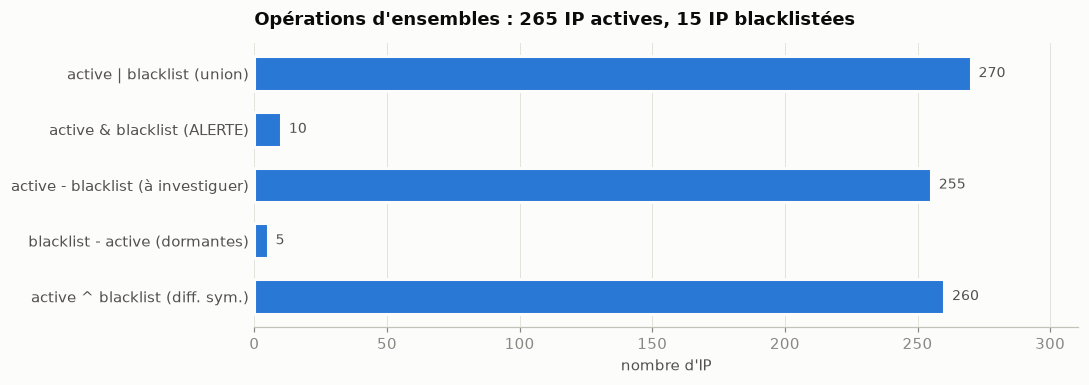

In [16]:
# Cardinalités des opérations d'ensembles (actives = IP en ERROR/CRITICAL)
labels = {
    "union": "active | blacklist (union)",
    "blacklisted_active": "active & blacklist (ALERTE)",
    "active_not_blacklisted": "active - blacklist (à investiguer)",
    "blacklisted_dormant": "blacklist - active (dormantes)",
    "symmetric_difference": "active ^ blacklist (diff. sym.)",
}
fig, ax = plt.subplots(figsize=(10, 3.6))
hbar(ax, list(labels.values()), [len(ip_sets[key]) for key in labels])
ax.set_title(f"Opérations d'ensembles : {len(aggregator.error_ips)} IP actives, "
             f"{len(blacklist)} IP blacklistées")
ax.set_xlabel("nombre d'IP")
fig.tight_layout()
plt.show()

## 4. Benchmark mémoire : mémoire pic vs nombre de lignes

On traite les N premières lignes du gros fichier (`python main.py generate --big`,
2 000 000 lignes, ~220 Mio) pour N = 10 000, 100 000 et 1 000 000, sous `tracemalloc`.
Si le gros fichier est absent, le benchmark utilise les échantillons.

In [17]:
big_sources = list(ingestion.discover_sources(BIG)) if BIG.exists() else []
if big_sources:
    sources, sizes = big_sources, [10_000, 100_000, 1_000_000]
else:
    sources, sizes = list(ingestion.discover_sources(SAMPLES)), [1_000, 10_000, 30_000]
total_bytes = sum(p.stat().st_size for p in sources)
total_lines = TRUTH["totals"]["lines"] if not big_sources else 2_000_000
results = run_scaling_benchmark(sources, sizes, blacklist=blacklist)
print(format_benchmark(results))
growth = results[-1].peak_mib / results[0].peak_mib
print(f"\nLignes x{results[-1].lines_read // results[0].lines_read} -> mémoire pic x{growth:.2f}")

  lignes lues      valides  durée (s)   lignes/s   pic mémoire  alertes
-----------------------------------------------------------------------
       10 000        9 784       5.12      1 952      0.32 Mio       18
      100 000       97 929      55.67      1 796      0.48 Mio      109
    1 000 000      979 477     573.38      1 744      1.79 Mio      129

Lignes x100 -> mémoire pic x5.63


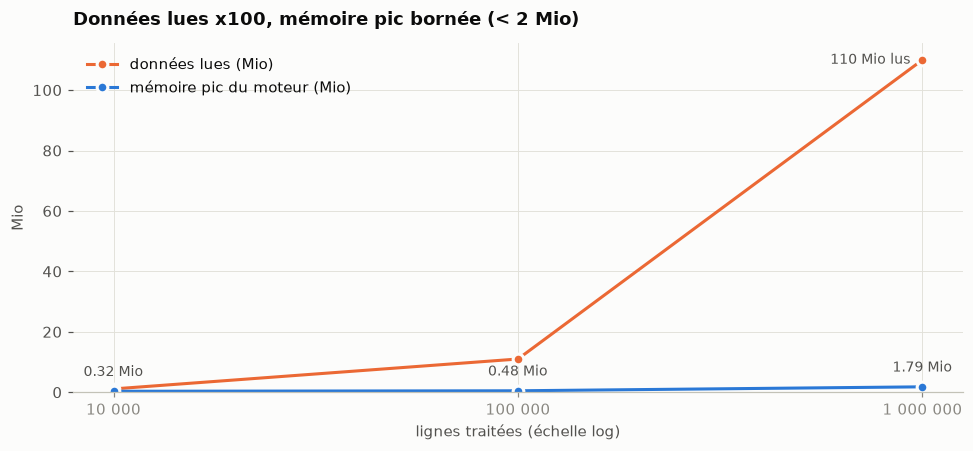

In [18]:
bytes_per_line = total_bytes / total_lines
read_mib = [r.lines_read * bytes_per_line / 2**20 for r in results]
peak_mib = [r.peak_mib for r in results]
lines = [r.lines_read for r in results]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(lines, read_mib, color=SERIES_2, linewidth=2, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, label="données lues (Mio)")
ax.plot(lines, peak_mib, color=SERIES_1, linewidth=2, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, label="mémoire pic du moteur (Mio)")
ax.set_xscale("log")
ax.set_xticks(lines, [fmt(n) for n in lines])
ax.minorticks_off()
ax.set_ylim(bottom=0)
ax.annotate(f"{read_mib[-1]:.0f} Mio lus", (lines[-1], read_mib[-1]), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center", color=INK_2, fontsize=9)
for x, y in zip(lines, peak_mib):  # valeur exacte de chaque mesure mémoire
    ax.annotate(f"{y:.2f} Mio", (x, y), xytext=(0, 10), textcoords="offset points",
                ha="center", color=INK_2, fontsize=9)
ax.set_title(f"Données lues x{lines[-1] // lines[0]}, mémoire pic bornée "
             f"(< {max(peak_mib) + 0.2:.0f} Mio)")
ax.set_xlabel("lignes traitées (échelle log)")
ax.set_ylabel("Mio")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Lecture.** Le volume de données lu croît linéairement avec le nombre de lignes
(110 Mio pour 1 million de lignes), alors que la mémoire pic du moteur reste de
l'ordre du mégaoctet. Elle ne dépend que du nombre d'entités distinctes : IP,
utilisateurs, heures et minutes (compteurs `defaultdict`, ensembles), escalades
(liste plafonnée) et tampons de connexion récents — jamais de la taille du fichier.
La légère hausse entre 100 000 et 1 000 000 de lignes correspond au remplissage de
ces structures bornées (une journée compte au plus 1 440 minutes) : sur le fichier
complet de 2 000 000 de lignes (220 Mio), `python main.py benchmark --sizes ...`
mesure **1,96 Mio**, contre 1,83 Mio à 1 million de lignes — la courbe plafonne.
C'est l'effet direct des générateurs (`yield` / `yield from`) et de l'agrégation en
une seule passe.

## 5. Correspondance barème → code

Numéros de ligne relevés par introspection (`inspect.getsourcelines`) sur le
code livré.

| Critère | Fichier | Fonction / objet | Ligne |
|---|---|---|---|
| `yield` (générateur) | `engine/ingestion.py` | `read_log_file` | 49 |
| `yield from` | `engine/ingestion.py` | `read_multiple_sources` | 53 |
| `with` (fermeture garantie) | `engine/ingestion.py` | `read_log_file` | 47 |
| dict typé `LogRecord` (TypedDict) | `engine/models.py` | `(module)` | 39 |
| tuple `(IP, Port, Protocole)` | `engine/models.py` | `(module)` | 25 |
| construction du tuple | `engine/parsing.py` | `parse_connection` | 103 |
| `map(str.strip, ...)` | `engine/pipeline.py` | `strip_lines` | 71 |
| `filter(None, ...)` | `engine/pipeline.py` | `drop_empty` | 81 |
| `filter(lambda ...)` x3 | `engine/pipeline.py` | `build_pipeline` | 255 |
| `map(normalize_record)` | `engine/pipeline.py` | `build_pipeline` | 267 |
| `map(lambda ...)` | `engine/analytics.py` | `collect_error_ips` | 61 |
| fonctions passées en argument | `engine/pipeline.py` | `build_filters` | 84 |
| f-strings (format) | `engine/pipeline.py` | `normalize_record` | 153 |
| `match-case` | `engine/pipeline.py` | `route_entry` | 185 |
| case `str()` | `engine/pipeline.py` | `route_entry` | 187 |
| case dict + `\|` + guard | `engine/pipeline.py` | `route_entry` | 193 |
| case `{..., **rest}` | `engine/pipeline.py` | `route_entry` | 202 |
| case tuple | `engine/pipeline.py` | `route_entry` | 208 |
| `set` | `engine/analytics.py` | `collect_error_ips` | 63 |
| set comprehension | `engine/analytics.py` | `collect_error_ips_comprehension` | 70 |
| `frozenset` | `engine/analytics.py` | `load_blacklist` | 95 |
| union `\|` | `engine/analytics.py` | `compare_ip_sets` | 117 |
| intersection `&` | `engine/analytics.py` | `compare_ip_sets` | 118 |
| différence `-` | `engine/analytics.py` | `compare_ip_sets` | 119 |
| différence sym. `^` | `engine/analytics.py` | `compare_ip_sets` | 121 |
| `defaultdict(int)` | `engine/analytics.py` | `count_by_level` | 130 |
| `defaultdict(list)` | `engine/analytics.py` | `group_events_by_ip` | 173 |
| `defaultdict(lambda: defaultdict(int))` | `engine/analytics.py` | `count_user_levels` | 152 |
| agrégation une passe | `engine/analytics.py` | `StreamAggregator` | 252 |
| `for` | `engine/detection.py` | `detect_brute_force` | 92 |
| `while` | `engine/detection.py` | `detect_brute_force` | 97 |
| `continue` | `engine/detection.py` | `detect_brute_force` | 101 |
| `break` (succès) | `engine/detection.py` | `detect_brute_force` | 121 |
| `break` (seuil atteint) | `engine/detection.py` | `detect_brute_force` | 144 |
| `else` de boucle | `engine/detection.py` | `detect_brute_force` | 146 |
| `*args, **kwargs` | `engine/rules.py` | `apply_security_rules` | 330 |
| `callable()` | `engine/rules.py` | `apply_security_rules` | 359 |
| `inspect.signature` | `engine/rules.py` | `select_kwargs` | 310 |
| registre + décorateur | `engine/rules.py` | `register_rule` | 52 |
| fonction -> fonction | `engine/rules.py` | `make_threshold_rule` | 296 |
| `globals()` | `engine/audit.py` | `audit_scope` | 130 |
| `locals()` (propre) | `engine/audit.py` | `audit_scope` | 132 |
| `audit_scope(locals())` | `main.py` | `cmd_run` | 199 |
| exceptions personnalisées | `engine/exceptions.py` | `(module)` | 38 |
| levée d'exception | `engine/parsing.py` | `parse_line` | 157 |
| capture sans arrêt | `engine/parsing.py` | `parse_stream` | 203 |
| typage (`TypedDict`, alias) | `engine/models.py` | `(module)` | 113 |

## 6. Limites et améliorations possibles

**Limites**

- *Ordre chronologique supposé* : la détection en flux suppose des événements
  globalement chronologiques par IP (fichiers traités dans l'ordre). Un écart
  temporel négatif clôt le tampon de l'IP, ce qui reste correct mais peut couper
  une attaque répartie sur deux fichiers non ordonnés.
- *Une alerte par IP* : dès que le seuil est atteint (`break`), l'analyse de l'IP
  s'arrête ; une seconde campagne de la même IP n'est pas rapportée séparément.
- *Règles de rafale et d'escalade* : calculées sur des compteurs par minute et sur le
  dernier `permission_denied` de chaque utilisateur (approximation volontaire pour
  garder une mémoire bornée).
- *Mono-cœur* : le débit (~15–20 000 lignes/s) est limité par le GIL et par le
  parsing en pur Python ; `tracemalloc` ralentit fortement le benchmark.
- *Formats figés* : trois formats connus ; un nouveau format nécessite un nouveau
  `case` dans le routage et une branche dans `parse_payload`.

**Améliorations**

- Lecture parallèle des fichiers (`multiprocessing`, un agrégateur par fichier puis
  fusion des `defaultdict` / ensembles, qui sont associatifs).
- Mode *suivi* (`tail -f`) : le pipeline étant un générateur, il peut consommer un
  flux infini ; ajouter une émission périodique des alertes.
- Fenêtre de détection paramétrable par service (SSH, RDP, HTTP…) et seuil adaptatif.
- Export vers un SIEM (syslog, JSON lines) et signature asymétrique des rapports.
- Configuration des règles par fichier (TOML) chargée dynamiquement dans le registre.